In [29]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch
from matplotlib.patches import PathPatch
from matplotlib.path import Path

In [59]:
df = pd.read_csv('FreezingTimes_CNO.csv')
print(df)

    Group   Cup  Recall Control
0       1   2.5     4.2       n
1       2  13.5     0.0       n
2       3   6.3    23.3       n
3       4   5.6    41.6       n
4       5   2.9    18.3       n
5       6   3.5    27.3       n
6       7  42.7    24.5       n
7       8   2.6     4.1       n
8       9  22.4    35.7       n
9      10   2.9     3.9       n
10     11   7.6    29.4       n
11     12   3.4    59.2       n
12     13  13.6    37.7       n
13     14   0.0    71.1       n
14     15   2.5     6.7       n
15     16   0.0    37.6       n
16     17   2.4    28.2       n
17     18   3.2    32.4       n
18     19   1.1    24.2       n
19     20   0.0    33.6       n
20     21   2.7    26.2       y
21     22   3.2    37.3       y
22     23   9.1    49.8       y
23     24   3.0    50.5       y
24     25   2.8     4.8       y
25     26  25.1    17.9       y
26     27   2.6    44.0       y
27     28   2.4    27.4       y
28     29   3.0    45.1       y
29     30   7.2    33.4       y
30     3

In [60]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

def map_half(i,num):
    if(i < num/2):
        return 0
    return 1

In [61]:
def marker(filled=False):
    if (filled):
        return 'o'
    pts = np.linspace(0, np.pi * 2, 24)
    circ = np.c_[np.sin(pts) / 2, -np.cos(pts) / 2]
    vert = np.r_[circ, circ[::-1] * .7]
    return Path(vert)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


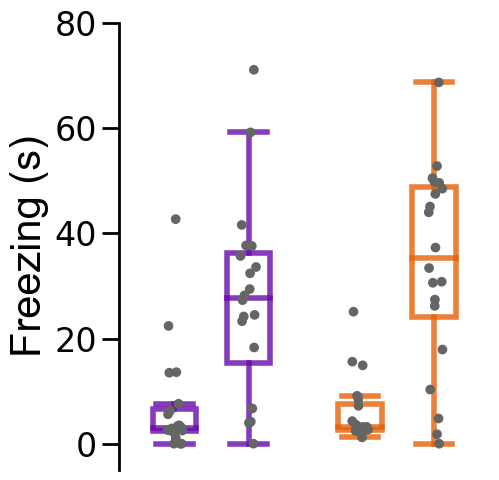

In [63]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']
colors = ["#646664","#646664"]
colors_boxplot = ["#680aab","#e66007"]
colors_boxplot_filling = ['none',"none"]



ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    order = ['n','y'],
    y='Left preference',
    x='control',
    marker=marker(True),
    palette=colors,
    size=7,
    jitter=0.09,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    order = ['n','y'],
    y='Left preference',
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=4,
    **PROPS
)

#plt.axhline(linewidth=2, color='lightgrey',ls='--')

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)


#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches


for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[map_half(i,len(box_patches))]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i%2==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

        

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)

plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social'], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['left'].set_color('black')


ax.set_xlabel("",fontsize=20)

###

ax.spines['left'].set_color('black')
ax.spines['left'].set_linewidth(2)

ax.set_ylim([-5,80])
#ax.set_yticks(np.arange(0,301,100), fontname='Arial')
#ax.set_yticklabels(['0','100','200','300'],fontname='Arial')

ax.set_xlim([-0.5,1.5])
ax.set_xticks([])

ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Freezing (s)', fontsize = 30, fontname='Arial')

plt.legend([],[], frameon=False)



fig = ax.get_figure()
adjust_box_widths(fig, 0.6)
fig.set_size_inches(5.1,4.9)
ax.tick_params(axis='y', which='major', labelsize=24)
ax.tick_params(axis='y', which='major', direction='out',length=12, labelsize=24, width=2)


plt.tight_layout()
fig.tight_layout()
fig.savefig("TimeFreezing_CNO.jpg",dpi=600,bbox_inches='tight')
plt.savefig('TimeFreezing_CNO.eps', format='eps', dpi=600)

